In [2]:
import os
os.getcwd()

'/Users/nanocell03/Documents/GitHub/TCancer_RareDiseases/src'

In [3]:
#Las variables categóricas vienen con códigos! no con el nombre
#Field = identificador o parámetros categórico
#creamos funcion po, la posicion de cada tipo dentro de field es el código

#Para clínico
def get_field_codes(clinical_dataset, target_fields):
    fields_names={field:xena.field_codes(host, clinical_dataset, [field])[0]['code'].split('\t') for field in target_fields}
    return fields_names

def create_clinical_df(host, clinical_dataset, clinical_samples, target_fields):   
    crossed_ref=[]
    clinical_columns = ['SampleID']
    fields_data={field:xena.dataset_fetch(host, clinical_dataset, clinical_samples, [field]) for field in target_fields}
    fields_names={field:xena.field_codes(host, clinical_dataset, [field])[0]['code'].split('\t') for field in target_fields}
    
    for field in target_fields:
        crossed_data = [fields_names[field][int(x)] if x != 'NaN' else '-' for x in fields_data[field][0]]
        crossed_ref.append(crossed_data)
        clinical_columns.append(field)
        if len(clinical_samples) != len(crossed_data):
            print(f'Error: El número de muestras es distinto al número de ocurrencias asociado a {field}')
            break
    
    clinical_df = pd.DataFrame(list(zip(clinical_samples, *crossed_ref)), columns=clinical_columns)
    return clinical_df
    
#Para expresión
def create_expression_df(host, exp_dataset, expression_samples, genes,expression_columns):
    expression_data = xena.dataset_probe_values(host, exp_dataset, expression_samples, genes)[1]
    expression_df = pd.DataFrame(list(zip(expression_samples, *expression_data)), columns=expression_columns)
    return expression_df

#Para DF final, el merge se queda con el menor número de muestras, ej: si tengo 2 df con 5 y 3 muestras, y solo dos son las comunes, el df se crea con esas 2 muestras.
def create_clinexp_df(clin_df, exp_df):
    clinexp_df = pd.merge(clin_df, exp_df, left_on='SampleID', right_on='SampleID')
    return clinexp_df

# 1. Carga de librerías y selección de cohort y host de Xena

### 1.1 Hosts disponibles:
- publicHub: https://ucscpublic.xenahubs.net
- tcgaHub: https://tcga.xenahubs.net
- icgcHub: https://icgc.xenahubs.net
- toilHub: https://toil.xenahubs.net
- pcawgHub: https://pcawg.xenahubs.net
- singlecellHub: https://singlecell.xenahubs.net
- pancanAtlasHub: https://pancanatlas.xenahubs.net
- treehouseHub: https://xena.treehouse.gi.ucsc.edu
- gdcHub: https://gdc.xenahubs.net
- reference: https://reference.xenahubs.net
  
### 1.2 Cohorts disponibles: (ej: dentro de toilHub)
- TCGA TARGET GTEx
- TCGA Pan-Cancer (PANCAN)
- TCGA and TARGET Pan-Cancer (PANCAN)
- TARGET Pan-Cancer (PANCAN)
- GTEX

In [4]:
import xenaPython as xena
import pandas as pd

cohort = 'TCGA TARGET GTEx'
host = xena.PUBLIC_HUBS['toilHub']

/opt/homebrew/Caskroom/miniconda/base/envs/tk/lib/python3.11/site-packages/xenaPython/__init__.py:110: FutureWarning: Possible nested set at position 7
  re.sub(r"^[^[]+[[]([^]]*)[]].*$", r"\1", query, flags=re.DOTALL))


# 2. Definimos funciones para obtener datos clínicos y de expresión de Xena
## Se deben escoger los datasets y parámetros para los datos clínicos y de expresión de manera manual

In [5]:
def get_clinical_features(host, cohort):
    datasets = xena.dataset_list(host,[cohort])
    clinical_datasets = [dataset for dataset in datasets if dataset['type']=='clinicalMatrix']
    
    features = []
    for dataset in clinical_datasets:
        for feature in xena.dataset_field(host, dataset['name']):
            features.append([dataset['name'], feature])
    features_df = pd.DataFrame(features, columns=['Dataset','Parameter'])
    return features_df

def get_expression_features(host, cohort):
    datasets = xena.dataset_list(host,[cohort])
    expression_datasets = [dataset for dataset in datasets if dataset['type']=='genomicMatrix']
    expression_info = []
    for dataset in expression_datasets:
        expression_info.append([dataset['name'], 
                                dataset['datasubtype'], 
                                dataset['count']])
    expression_info_df = pd.DataFrame(expression_info, columns=['Name','Subtype','Sample count'])
    return expression_info_df

get_clinical_features(host, cohort)

,Dataset,Parameter
0,TCGA_GTEX_category.txt,TCGA_GTEX_main_category
1,TCGA_GTEX_category.txt,sampleID
2,TCGA_survival_data,DFI
3,TCGA_survival_data,DFI.time
4,TCGA_survival_data,DSS
5,TCGA_survival_data,DSS.time
6,TCGA_survival_data,OS
7,TCGA_survival_data,OS.time
8,TCGA_survival_data,PFI
9,TCGA_survival_data,PFI.time


In [6]:
get_expression_features(host, cohort)

,Name,Subtype,Sample count
0,TCGA-GTEx-TARGET-gene-exp-counts.deseq2-normal...,gene expression RNAseq,19039
1,TcgaTargetGtex_expected_count,transcript expression RNAseq,19109
2,TcgaTargetGtex_gene_expected_count,gene expression RNAseq,19109
3,TcgaTargetGtex_rsem_gene_fpkm,gene expression RNAseq,19131
4,TcgaTargetGtex_rsem_gene_tpm,gene expression RNAseq,19131
5,TcgaTargetGtex_RSEM_Hugo_norm_count,gene expression RNAseq,19120
6,TcgaTargetGtex_RSEM_isoform_fpkm,transcript expression RNAseq,19129
7,TcgaTargetGtex_rsem_isoform_tpm,transcript expression RNAseq,19131
8,TcgaTargetGtex_rsem_isopct,transcript expression RNAseq,19131


In [7]:
#Para clinico, necesita la sintáxis (host, dataset, samples, fields)
target_fields = ['_primary_site','_sample_type']
clinical_dataset= 'TcgaTargetGTEX_phenotype.txt'
clinical_samples = xena.dataset_samples(host, clinical_dataset, None)

#Para expresión, necesita la sintáxis (host, dataset, samples, genes, expression_columns)
genes = ['BMPR1B', 'ACVR2A', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'ACVRL1',
       'TGFBR2', 'ACVR1', 'ACVR2B', 'BMPR2', 'AMHR2', 'ACVR1C'] #Solo sirve para genes HUGO, de tener ENSEMBL hay que escribir el código completo.
expression_dataset = 'TcgaTargetGtex_RSEM_Hugo_norm_count'
expression_samples = xena.dataset_samples(host, expression_dataset, None)
expression_columns = ['SampleID'] + genes

In [8]:
clin_df = create_clinical_df(host, clinical_dataset, clinical_samples, target_fields)
exp_df = create_expression_df(host, expression_dataset, expression_samples, genes, expression_columns)

clinexp = create_clinexp_df(clin_df, exp_df)
for field in target_fields:
    print(clinexp[field].unique())

['Eye' 'Endometrium' 'Uterus' 'Thyroid Gland' 'Thymus' 'Testis' 'Stomach'
 'Skin' 'Soft tissue,Bone' 'Rectum' 'Prostate' 'Paraganglia' 'Pancreas'
 'Ovary' 'Lining of body cavities' 'Lung' 'Liver' 'Kidney'
 'Head and Neck region' 'Brain' 'Esophagus' 'Lymphatic tissue' 'Colon'
 'Bile duct' 'Cervix' 'Breast' 'Bladder' 'Adrenal gland'
 'White blood cell' '-' 'Bone Marrow' 'Cervix Uteri' 'Fallopian Tube'
 'Blood' 'Blood Vessel' 'Pituitary' 'Heart' 'Nerve' 'Small Intestine'
 'Spleen' 'Thyroid' 'Adrenal Gland' 'Salivary Gland' 'Vagina'
 'Adipose Tissue' 'Muscle' 'Sympathetic�Nervous System']
['Primary Tumor' 'Solid Tissue Normal' 'Recurrent Tumor' 'Metastatic'
 'Additional - New Primary' 'Additional Metastatic'
 'Primary Blood Derived Cancer - Peripheral Blood' 'Control Analyte'
 'Cell Line' 'Normal Tissue' 'Recurrent Solid Tumor' 'Primary Solid Tumor'
 'Recurrent Blood Derived Cancer - Bone Marrow'
 'Primary Blood Derived Cancer - Bone Marrow'
 'Post treatment Blood Cancer - Bone Marrow'
 'P

In [9]:
clinexp

,SampleID,_primary_site,_sample_type,BMPR1B,ACVR2A,BMPR1A,ACVR1B,TGFBR1,ACVRL1,TGFBR2,ACVR1,ACVR2B,BMPR2,AMHR2,ACVR1C
0,TCGA-V4-A9EE-01,Eye,Primary Tumor,9.820,8.718,10.350,10.430,10.550,8.735,10.040,10.010,8.398,11.970,0.000,5.476
1,TCGA-VD-AA8N-01,Eye,Primary Tumor,6.058,6.943,8.813,10.200,9.471,10.200,9.790,8.708,7.103,9.963,0.000,5.134
2,TCGA-V4-A9EI-01,Eye,Primary Tumor,6.404,8.505,10.330,10.260,10.390,9.488,9.491,9.835,8.219,10.860,1.047,6.567
3,TCGA-VD-AA8O-01,Eye,Primary Tumor,3.456,7.158,8.336,9.895,9.153,8.860,10.090,9.952,7.094,10.130,0.998,1.582
4,TCGA-WC-A888-01,Eye,Primary Tumor,7.931,8.401,9.689,10.120,10.590,8.729,9.458,9.683,7.931,10.700,0.000,4.668
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19115,TARGET-20-PANPKN-09,White blood cell,Primary Blood Derived Cancer - Bone Marrow,0.000,4.529,3.290,10.810,12.070,5.747,13.190,7.218,6.554,10.780,3.290,0.000
19116,TARGET-20-PANLIR-09,White blood cell,Primary Blood Derived Cancer - Bone Marrow,0.000,4.763,6.319,9.797,10.910,6.674,11.180,8.376,6.251,8.267,4.481,2.236
19117,TARGET-20-PAPAWN-09,White blood cell,Primary Blood Derived Cancer - Bone Marrow,0.000,3.690,0.000,8.181,8.213,6.474,10.270,8.312,4.964,7.945,1.501,0.000
19118,TARGET-20-PANPTM-09,White blood cell,Primary Blood Derived Cancer - Bone Marrow,0.000,3.090,0.000,8.472,8.624,7.369,10.650,8.453,5.611,7.008,3.377,0.000


In [10]:
clinexp['BMPR1B'].mean

<bound method Series.mean of 0        9.820
1        6.058
2        6.404
3        3.456
4        7.931
         ...  
19115    0.000
19116    0.000
19117    0.000
19118    0.000
19119    0.000
Name: BMPR1B, Length: 19120, dtype: float64>

# 3. Ahora podemos seleccionar los fields que queramos graficar

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Median: _sample_type
Metastatic             9.281
Normal Tissue          5.460
Primary Tumor          9.080
Solid Tissue Normal    7.428
Name: BMPR1B, dtype: float64
Mean: _sample_type
Metastatic             8.777429
Normal Tissue          5.500564
Primary Tumor          9.634161
Solid Tissue Normal    7.457027
Name: BMPR1B, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: BMPR1B, dtype: int64
Min: _sample_type
Metastatic             1.342
Normal Tissue          0.000
Primary Tumor          0.000
Solid Tissue Normal    3.325
Name: BMPR1B, dtype: float64
Max: _sample_type
Metastatic             15.590
Normal Tissue           9.669
Primary Tumor          16.750
Solid Tissue Normal    12.430
Name: BMPR1B, dtype: float64


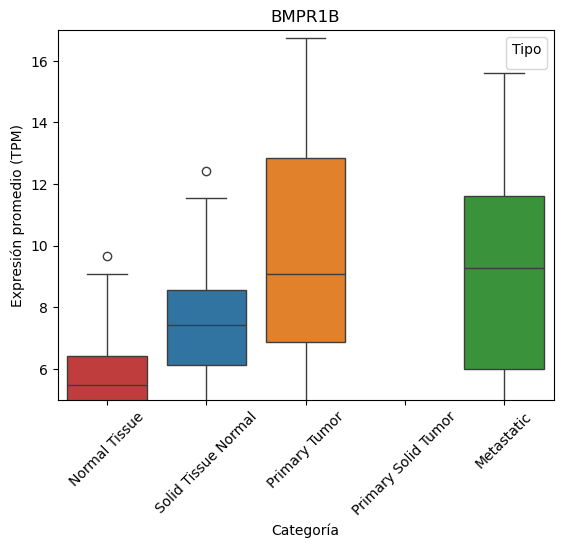

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Median: _sample_type
Metastatic             8.2540
Normal Tissue          9.6680
Primary Tumor          8.9415
Solid Tissue Normal    9.9670
Name: ACVR2A, dtype: float64
Mean: _sample_type
Metastatic             8.209286
Normal Tissue          9.683737
Primary Tumor          8.921079
Solid Tissue Normal    9.969106
Name: ACVR2A, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: ACVR2A, dtype: int64
Min: _sample_type
Metastatic             7.285
Normal Tissue          8.592
Primary Tumor          5.341
Solid Tissue Normal    9.042
Name: ACVR2A, dtype: float64
Max: _sample_type
Metastatic              9.324
Normal Tissue          10.520
Primary Tumor          11.410
Solid Tissue Normal    11.340
Name: ACVR2A, dtype: float64


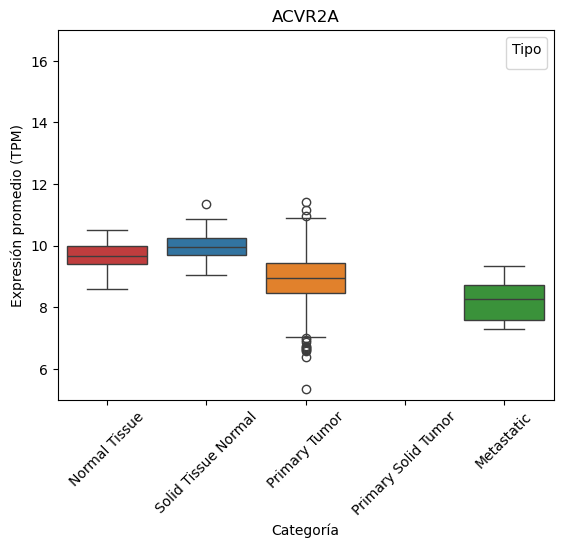

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Median: _sample_type
Metastatic             10.73
Normal Tissue          10.64
Primary Tumor          10.59
Solid Tissue Normal    11.29
Name: BMPR1A, dtype: float64
Mean: _sample_type
Metastatic             10.253857
Normal Tissue          10.629363
Primary Tumor          10.541837
Solid Tissue Normal    11.256637
Name: BMPR1A, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: BMPR1A, dtype: int64
Min: _sample_type
Metastatic              8.229
Normal Tissue           9.774
Primary Tumor           6.513
Solid Tissue Normal    10.250
Name: BMPR1A, dtype: float64
Max: _sample_type
Metastatic             11.22
Normal Tissue          11.21
Primary Tumor          12.70
Solid Tissue Normal    12.11
Name: BMPR1A, dtype: float64


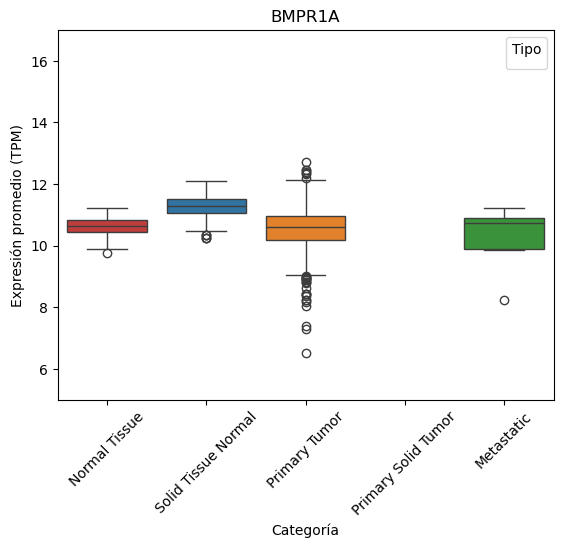

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Median: _sample_type
Metastatic             10.820
Normal Tissue          10.710
Primary Tumor          11.015
Solid Tissue Normal    10.860
Name: ACVR1B, dtype: float64
Mean: _sample_type
Metastatic             11.121429
Normal Tissue          10.709615
Primary Tumor          10.953312
Solid Tissue Normal    10.848637
Name: ACVR1B, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: ACVR1B, dtype: int64
Min: _sample_type
Metastatic             10.210
Normal Tissue           9.708
Primary Tumor           8.402
Solid Tissue Normal     9.894
Name: ACVR1B, dtype: float64
Max: _sample_type
Metastatic             12.09
Normal Tissue          12.02
Primary Tumor          12.98
Solid Tissue Normal    11.57
Name: ACVR1B, dtype: float64


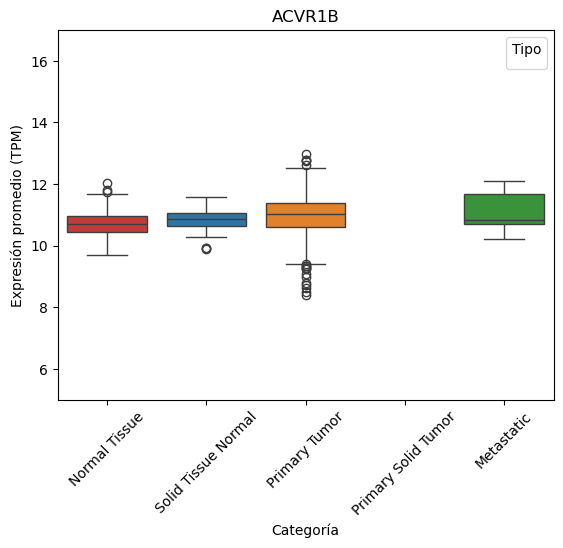

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Median: _sample_type
Metastatic             11.25
Normal Tissue          10.46
Primary Tumor          11.26
Solid Tissue Normal    11.56
Name: TGFBR1, dtype: float64
Mean: _sample_type
Metastatic             10.685857
Normal Tissue          10.471492
Primary Tumor          11.256854
Solid Tissue Normal    11.526372
Name: TGFBR1, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: TGFBR1, dtype: int64
Min: _sample_type
Metastatic              9.233
Normal Tissue           9.439
Primary Tumor           8.083
Solid Tissue Normal    10.450
Name: TGFBR1, dtype: float64
Max: _sample_type
Metastatic             11.80
Normal Tissue          11.63
Primary Tumor          15.35
Solid Tissue Normal    12.92
Name: TGFBR1, dtype: float64


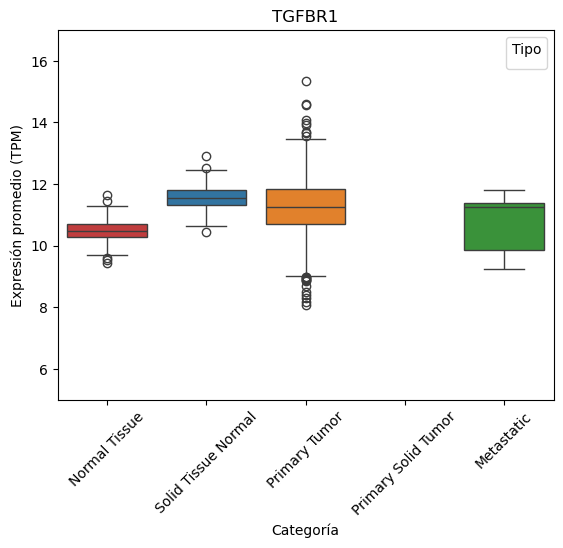

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Median: _sample_type
Metastatic              9.9810
Normal Tissue          11.5900
Primary Tumor           9.5065
Solid Tissue Normal    10.6500
Name: ACVRL1, dtype: float64
Mean: _sample_type
Metastatic              9.336143
Normal Tissue          11.484006
Primary Tumor           9.498082
Solid Tissue Normal    10.580195
Name: ACVRL1, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: ACVRL1, dtype: int64
Min: _sample_type
Metastatic             8.055
Normal Tissue          9.498
Primary Tumor          6.182
Solid Tissue Normal    8.654
Name: ACVRL1, dtype: float64
Max: _sample_type
Metastatic             10.28
Normal Tissue          13.05
Primary Tumor          12.53
Solid Tissue Normal    12.28
Name: ACVRL1, dtype: float64


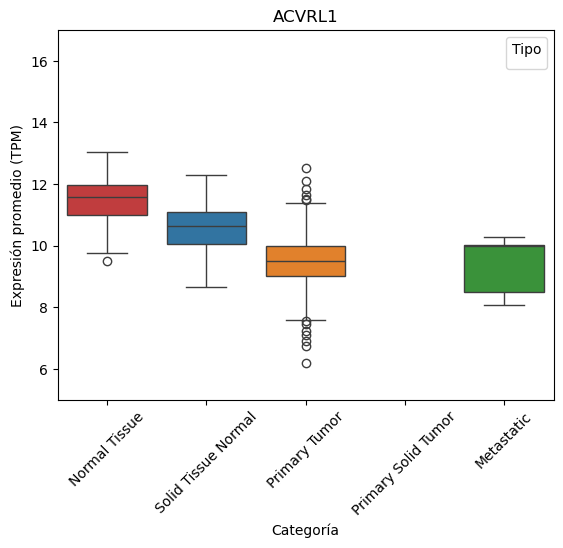

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Median: _sample_type
Metastatic             11.79
Normal Tissue          14.03
Primary Tumor          11.57
Solid Tissue Normal    13.98
Name: TGFBR2, dtype: float64
Mean: _sample_type
Metastatic             11.545143
Normal Tissue          14.009162
Primary Tumor          11.513970
Solid Tissue Normal    13.916814
Name: TGFBR2, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: TGFBR2, dtype: int64
Min: _sample_type
Metastatic              9.916
Normal Tissue          12.320
Primary Tumor           6.017
Solid Tissue Normal    11.660
Name: TGFBR2, dtype: float64
Max: _sample_type
Metastatic             13.02
Normal Tissue          15.31
Primary Tumor          16.67
Solid Tissue Normal    15.29
Name: TGFBR2, dtype: float64


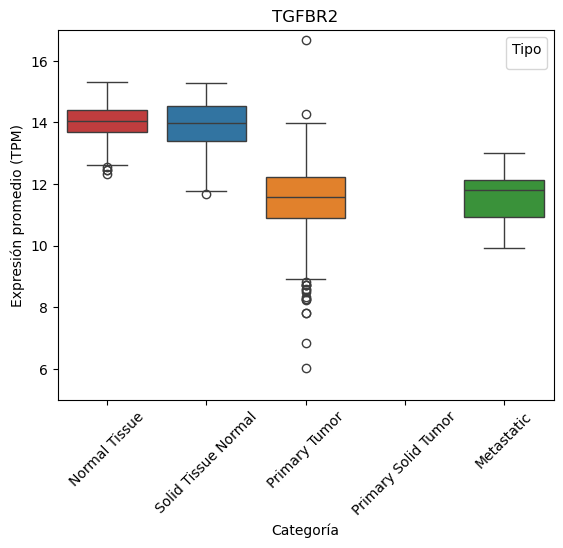

Median: _sample_type
Metastatic             10.53
Normal Tissue          10.50
Primary Tumor          10.55
Solid Tissue Normal    11.03
Name: ACVR1, dtype: float64
Mean: _sample_type
Metastatic             10.374000
Normal Tissue          10.471000
Primary Tumor          10.510159
Solid Tissue Normal    11.038850
Name: ACVR1, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: ACVR1, dtype: int64
Min: _sample_type
Metastatic              9.528
Normal Tissue           9.068
Primary Tumor           7.536
Solid Tissue Normal    10.400
Name: ACVR1, dtype: float64
Max: _sample_type
Metastatic             10.86
Normal Tissue          11.58
Primary Tumor          13.26
Solid Tissue Normal    11.99
Name: ACVR1, dtype: float64


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


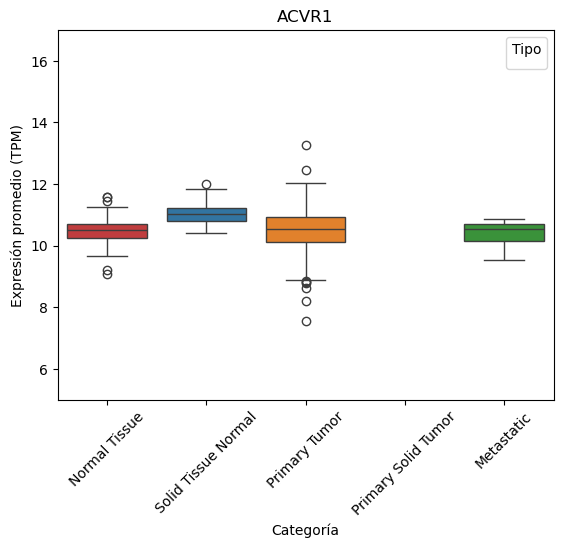

Median: _sample_type
Metastatic             9.1200
Normal Tissue          8.7430
Primary Tumor          9.2645
Solid Tissue Normal    9.4210
Name: ACVR2B, dtype: float64
Mean: _sample_type
Metastatic             9.158714
Normal Tissue          8.744670
Primary Tumor          9.263777
Solid Tissue Normal    9.327619
Name: ACVR2B, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: ACVR2B, dtype: int64
Min: _sample_type
Metastatic             8.268
Normal Tissue          6.897
Primary Tumor          6.405
Solid Tissue Normal    7.397
Name: ACVR2B, dtype: float64
Max: _sample_type
Metastatic              9.948
Normal Tissue           9.890
Primary Tumor          12.090
Solid Tissue Normal    10.540
Name: ACVR2B, dtype: float64


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


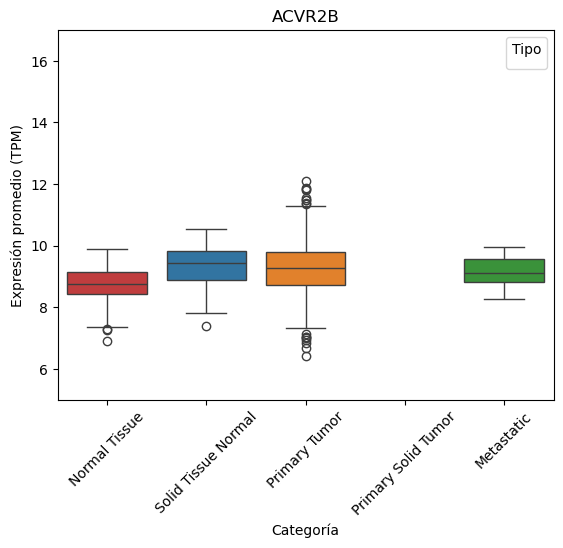

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Median: _sample_type
Metastatic             11.970
Normal Tissue          11.760
Primary Tumor          12.105
Solid Tissue Normal    12.680
Name: BMPR2, dtype: float64
Mean: _sample_type
Metastatic             12.000000
Normal Tissue          11.745531
Primary Tumor          12.055867
Solid Tissue Normal    12.601504
Name: BMPR2, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: BMPR2, dtype: int64
Min: _sample_type
Metastatic             11.500
Normal Tissue          10.290
Primary Tumor           8.936
Solid Tissue Normal    11.080
Name: BMPR2, dtype: float64
Max: _sample_type
Metastatic             12.64
Normal Tissue          13.16
Primary Tumor          14.30
Solid Tissue Normal    13.67
Name: BMPR2, dtype: float64


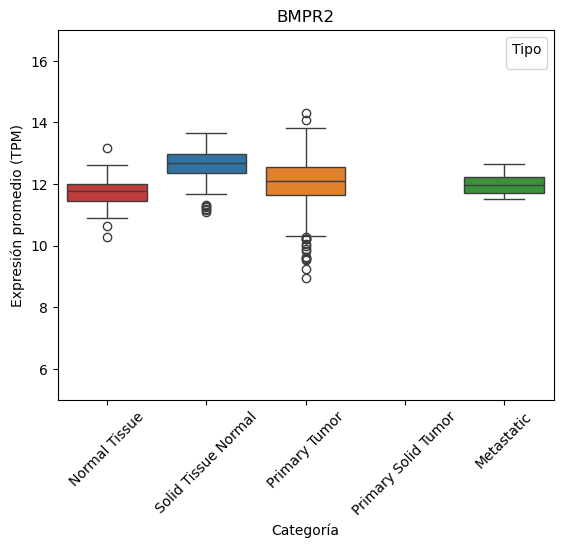

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Median: _sample_type
Metastatic             2.2090
Normal Tissue          1.7880
Primary Tumor          1.5965
Solid Tissue Normal    1.6450
Name: AMHR2, dtype: float64
Mean: _sample_type
Metastatic             2.850143
Normal Tissue          1.759049
Primary Tumor          1.697831
Solid Tissue Normal    1.601148
Name: AMHR2, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: AMHR2, dtype: int64
Min: _sample_type
Metastatic             0.0
Normal Tissue          0.0
Primary Tumor          0.0
Solid Tissue Normal    0.0
Name: AMHR2, dtype: float64
Max: _sample_type
Metastatic             9.793
Normal Tissue          4.569
Primary Tumor          6.588
Solid Tissue Normal    6.360
Name: AMHR2, dtype: float64


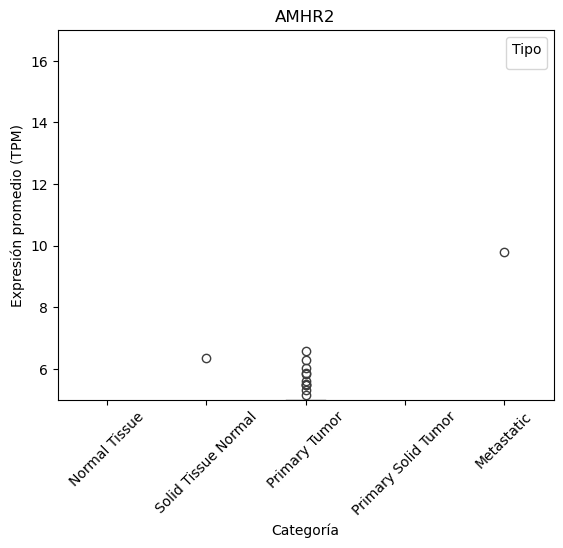

Median: _sample_type
Metastatic              4.279
Normal Tissue           9.278
Primary Tumor           5.133
Solid Tissue Normal    10.260
Name: ACVR1C, dtype: float64
Mean: _sample_type
Metastatic              4.826857
Normal Tissue           9.003469
Primary Tumor           5.219537
Solid Tissue Normal    10.112088
Name: ACVR1C, dtype: float64
Counts: _sample_type
Metastatic                7
Normal Tissue           179
Primary Tumor          1092
Solid Tissue Normal     113
Name: ACVR1C, dtype: int64
Min: _sample_type
Metastatic             3.499
Normal Tissue          4.133
Primary Tumor          0.000
Solid Tissue Normal    3.857
Name: ACVR1C, dtype: float64
Max: _sample_type
Metastatic              7.883
Normal Tissue          13.180
Primary Tumor          11.150
Solid Tissue Normal    14.690
Name: ACVR1C, dtype: float64


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


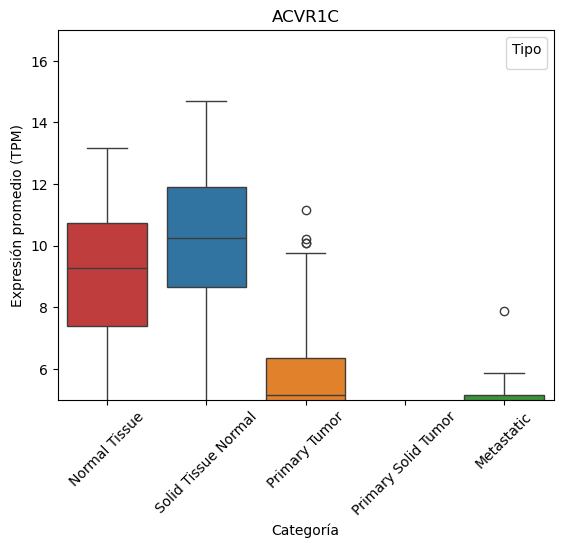

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define los tipos de cáncer que deseas analizar
site = ['Breast']

type = ['Normal Tissue','Solid Tissue Normal', 'Primary Tumor', 'Primary Solid Tumor', 'Metastatic']

if len(site)!=0 and len(type)!=0:
    clinexp_filtered = clinexp.loc[(clinexp['_primary_site'].isin(site) & (clinexp['_sample_type'].isin(type)))]
if len(site)==0 and len(type)!=0:
    clinexp_filtered = clinexp.loc[(clinexp['_sample_type'].isin(type))]
if len(site)!=0 and len(type)==0:
    clinexp_filtered = clinexp.loc[(clinexp['_primary_site'].isin(site))]

#Gráfico

for gene in genes:
    median = clinexp_filtered.groupby('_sample_type')[gene].median()
    mean = clinexp_filtered.groupby('_sample_type')[gene].mean()
    counts = clinexp_filtered.groupby('_sample_type')[gene].count()
    min = clinexp_filtered.groupby('_sample_type')[gene].min()
    max = clinexp_filtered.groupby('_sample_type')[gene].max()
    
    print('Median:', median)
    print('Mean:', mean)
    print('Counts:', counts)
    print('Min:',min)
    print('Max:',max)
    sns.boxplot(x='_sample_type', 
                y=gene, 
                hue='_sample_type', 
                data=clinexp_filtered,
                order=type)
    
    plt.title(gene)
    plt.xlabel('Categoría')
    plt.ylabel('Expresión promedio (TPM)')
    plt.ylim(5,17)
    plt.xticks(rotation=45) 
    plt.legend(title='Tipo')
    
    plt.show()

/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/1756825980.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clinexp_filtered[gen] = clinexp_filtered[gen] / clinexp_filtered[gen].max()


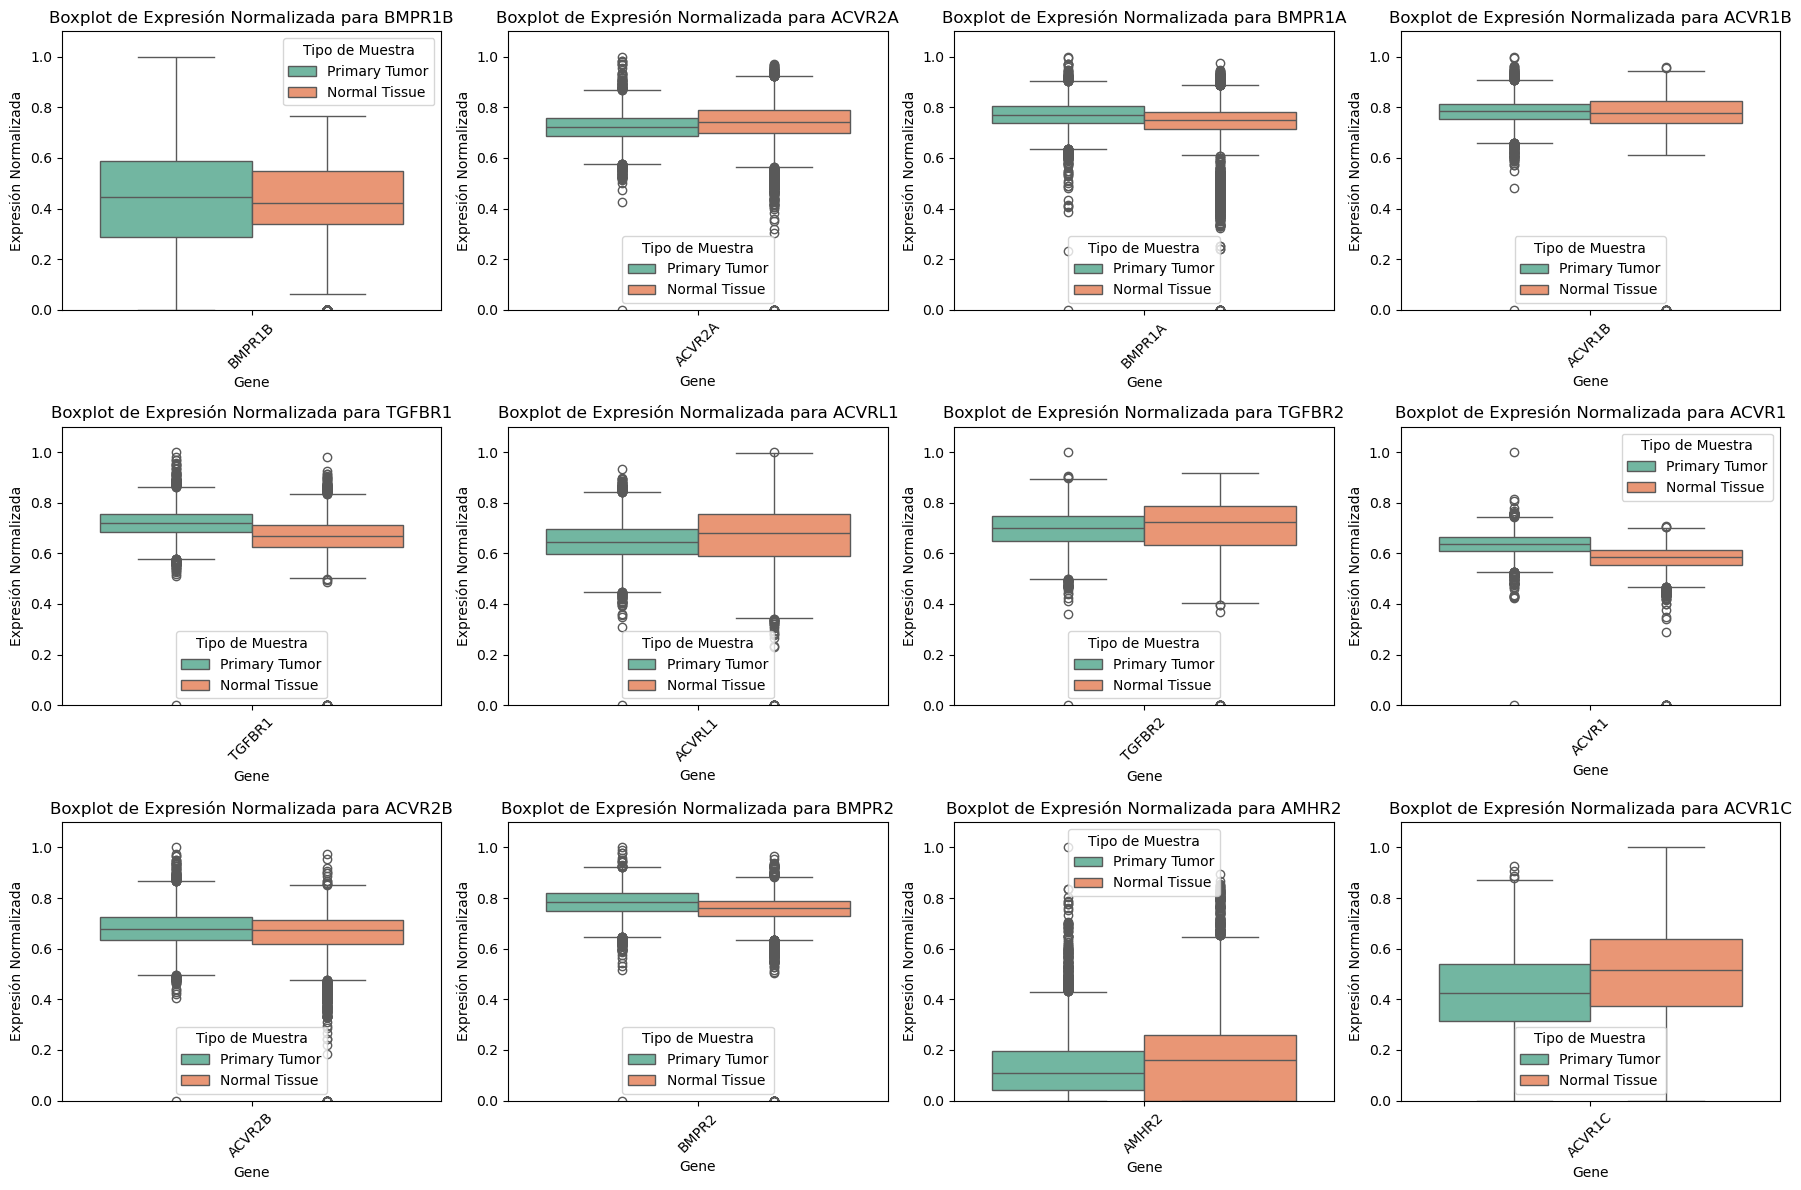

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define los genes que deseas analizar
gen_list = ['BMPR1B', 'ACVR2A', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'ACVRL1',
            'TGFBR2', 'ACVR1', 'ACVR2B', 'BMPR2', 'AMHR2', 'ACVR1C']

# Define los tipos de cáncer y el tipo de muestra que deseas analizar
sites = ['Uterus', 'Skin', 'Colon', 'Lung', 'Stomach', 'Pancreas', 'Breast',
'Head and Neck region', 'Liver', 'Brain', 'Bladder', 'Cervix', 'Kidney', 'Ovary',
'Prostate', 'Blood']

sample_types = ['Normal Tissue', 'Primary Tumor']

# Filtrar los datos para Normal Tissue y Primary Tumor
clinexp_filtered = clinexp.loc[
    (clinexp['_primary_site'].isin(sites)) & 
    (clinexp['_sample_type'].isin(sample_types))
]

# Normalizar los datos de expresión
for gen in gen_list:
    clinexp_filtered[gen] = clinexp_filtered[gen] / clinexp_filtered[gen].max()

# Convertir los datos a formato largo para seaborn
clinexp_long = clinexp_filtered.melt(id_vars=['_primary_site', '_sample_type'], 
                                      value_vars=gen_list, 
                                      var_name='Gene', 
                                      value_name='Normalized Expression')

# Configuración de la figura para los boxplots
num_genes = len(gen_list)
cols = 4
rows = (num_genes + cols - 1) // cols  # Calcular el número de filas necesarias

plt.figure(figsize=(18, 4 * rows))

# Crear un boxplot para cada gen
for i, gene in enumerate(gen_list):
    plt.subplot(rows, cols, i + 1)  # Crear subgráfico
    sns.boxplot(x='Gene', y='Normalized Expression', hue='_sample_type', 
                data=clinexp_long[clinexp_long['Gene'] == gene], palette='Set2')
    
    plt.title(f'Boxplot de Expresión Normalizada para {gene}')
    plt.xlabel('Gene')
    plt.ylabel('Expresión Normalizada')
    plt.ylim(0, 1.1)  # Ajustar el límite del eje y si es necesario
    plt.legend(title='Tipo de Muestra')
    plt.xticks(rotation=45)

plt.tight_layout()  # Ajustar el espaciado entre subgráficos
plt.show()


In [13]:
clinexp_long['_primary_site'].unique()

array(['Uterus', 'Stomach', 'Skin', 'Prostate', 'Pancreas', 'Ovary',
       'Lung', 'Liver', 'Kidney', 'Head and Neck region', 'Brain',
       'Colon', 'Cervix', 'Breast', 'Bladder', 'Blood'], dtype=object)

In [14]:
clinexp['_primary_site'].unique()

array(['Eye', 'Endometrium', 'Uterus', 'Thyroid Gland', 'Thymus',
       'Testis', 'Stomach', 'Skin', 'Soft tissue,Bone', 'Rectum',
       'Prostate', 'Paraganglia', 'Pancreas', 'Ovary',
       'Lining of body cavities', 'Lung', 'Liver', 'Kidney',
       'Head and Neck region', 'Brain', 'Esophagus', 'Lymphatic tissue',
       'Colon', 'Bile duct', 'Cervix', 'Breast', 'Bladder',
       'Adrenal gland', 'White blood cell', '-', 'Bone Marrow',
       'Cervix Uteri', 'Fallopian Tube', 'Blood', 'Blood Vessel',
       'Pituitary', 'Heart', 'Nerve', 'Small Intestine', 'Spleen',
       'Thyroid', 'Adrenal Gland', 'Salivary Gland', 'Vagina',
       'Adipose Tissue', 'Muscle', 'Sympathetic�Nervous System'],
      dtype=object)

In [15]:
clinexp_long

,_primary_site,_sample_type,Gene,Normalized Expression
0,Uterus,Primary Tumor,BMPR1B,0.536299
1,Uterus,Primary Tumor,BMPR1B,0.516657
2,Uterus,Primary Tumor,BMPR1B,0.585791
3,Uterus,Primary Tumor,BMPR1B,0.452537
4,Uterus,Primary Tumor,BMPR1B,0.567761
...,...,...,...,...
129151,Ovary,Normal Tissue,ACVR1C,0.741806
129152,Ovary,Normal Tissue,ACVR1C,0.686950
129153,Ovary,Normal Tissue,ACVR1C,0.551290
129154,Ovary,Normal Tissue,ACVR1C,0.351442


# Graficamos los genes y sites seleccionados
## Grafico de tipo violin normalizado

/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/4196710676.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clinexp_filtered[gen] = clinexp_filtered[gen] / clinexp_filtered[gen].max()


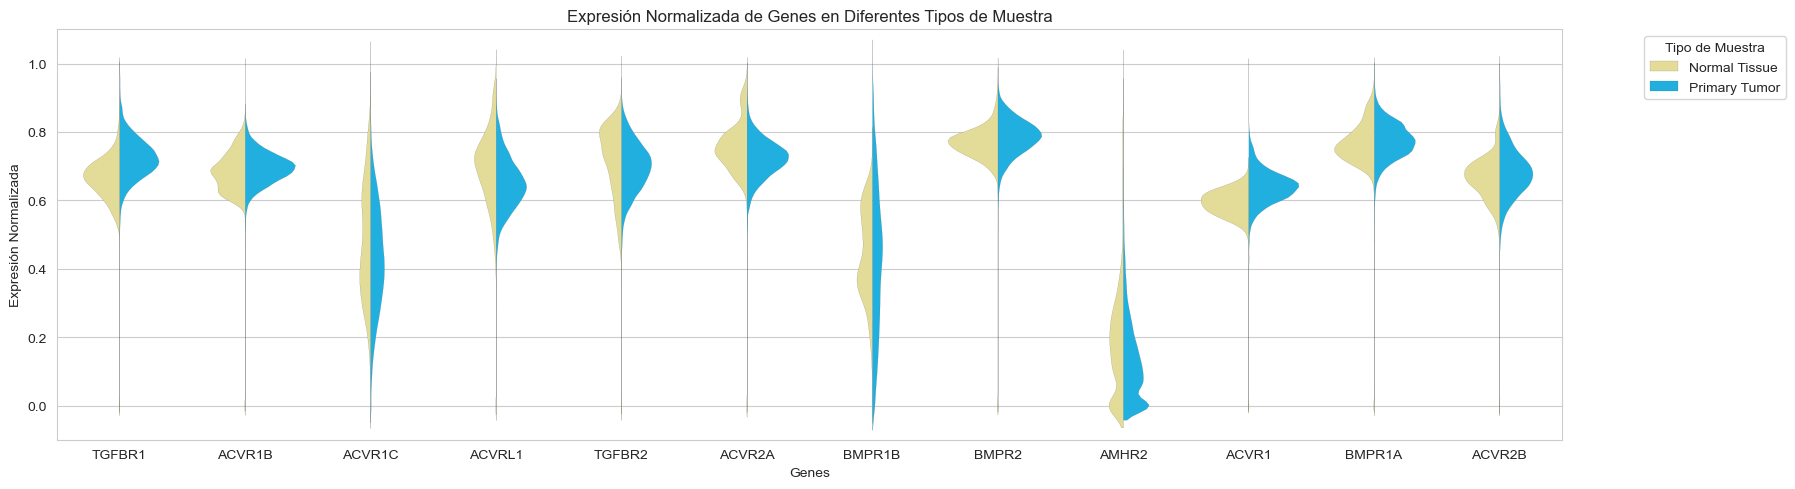

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define los genes que deseas analizar
gen_list = ['BMPR1B', 'ACVR2A', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'ACVRL1',
            'TGFBR2', 'ACVR1', 'ACVR2B', 'BMPR2', 'AMHR2', 'ACVR1C']

# Define los tipos de cáncer y el tipo de muestra que deseas analizar
sites = ['Breast', 'Uterus', 'Thyroid Gland', 'Stomach', 'Skin', 
         'Prostate', 'Pancreas', 'Ovary', 'Lung', 'Liver', 
         'Kidney', 'Head and Neck region', 'Brain', 'Esophagus', 
         'Colon', 'Cervix', 'Bladder', 'Heart']

sample_types = ['Normal Tissue', 'Primary Tumor']

# Filtrar los datos para Normal Tissue y Primary Tumor
clinexp_filtered = clinexp.loc[
    (clinexp['_primary_site'].isin(sites)) & 
    (clinexp['_sample_type'].isin(sample_types))
]

# Normalizar los datos de expresión
for gen in gen_list:
    clinexp_filtered[gen] = clinexp_filtered[gen] / clinexp_filtered[gen].max()

# Convertir los datos a formato largo para seaborn
clinexp_long = clinexp_filtered.melt(id_vars=['_primary_site', '_sample_type'], 
                                      value_vars=gen_list, 
                                      var_name='Gene', 
                                      value_name='Normalized Expression')


# Configurar el estilo para eliminar líneas externas
sns.set_style("whitegrid")  # Cambia a 'white' si prefieres un fondo completamente blanco

# Configurar la figura con varias columnas
plt.figure(figsize=(18, 5))

# Definir la paleta con los dos colores seleccionados
custom_palette = ['#F0E68C', '#00BFFF']  # Amarillo y azul oscuro

# Crear el violin plot usando la paleta personalizada
sns.violinplot(data=clinexp_long, 
               palette=custom_palette, 
               y="Normalized Expression", 
               x='Gene', 
               hue="_sample_type", 
               split=True, 
               inner=None,  # Remueve las líneas/puntos internos
               linewidth=0.1,  # Establece el grosor de las líneas externas a 0
               order=['TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B',
                      'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B'],
               hue_order=['Normal Tissue', 'Primary Tumor'])

# Personalización de la gráfica
plt.title('Expresión Normalizada de Genes en Diferentes Tipos de Muestra')
plt.xlabel('Genes')
plt.ylabel('Expresión Normalizada')
plt.ylim(-0.1, 1.1)  # Ajustar el límite del eje y si es necesario
plt.legend(title='Tipo de Muestra', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Guardar el gráfico en formato PNG antes de mostrarlo
plt.savefig("violin_plot.png", format='png', dpi=300, bbox_inches='tight')

# Mostrar el gráfico
plt.show()



/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/410952727.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clinexp_filtered[gen] = clinexp_filtered[gen] / clinexp_filtered[gen].max()


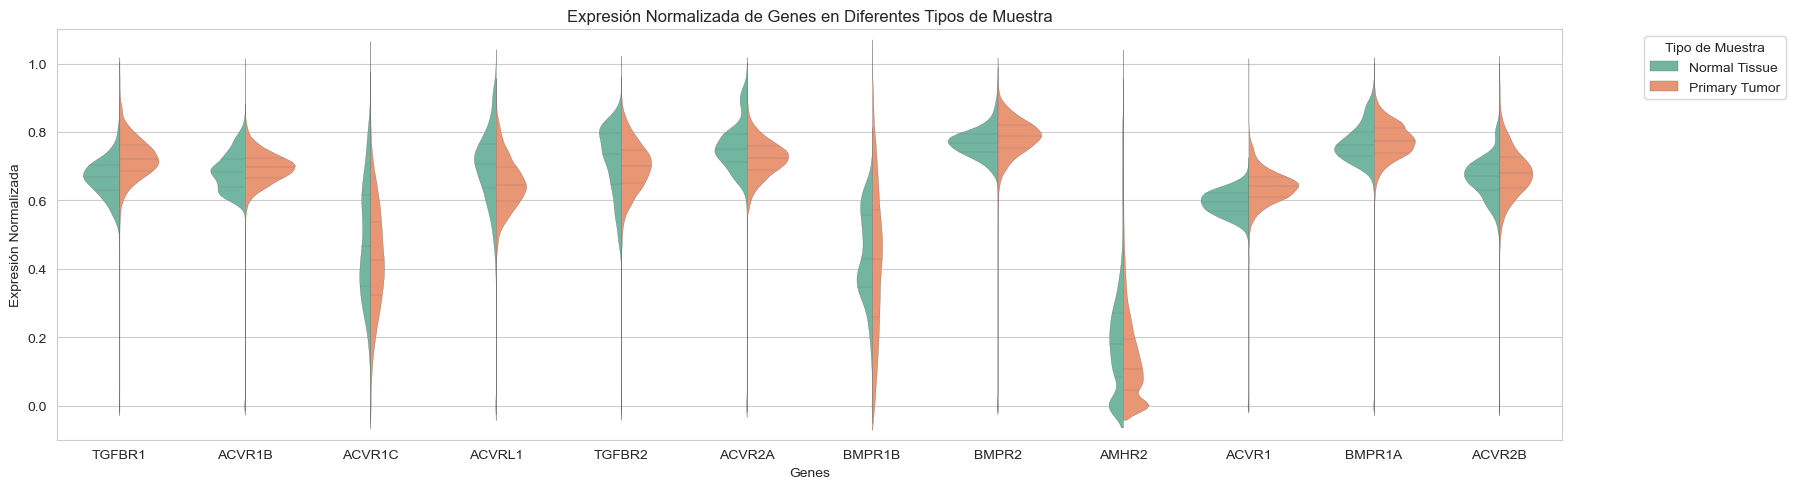

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt


# Define los genes que deseas analizar
gen_list = ['BMPR1B', 'ACVR2A', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'ACVRL1',
            'TGFBR2', 'ACVR1', 'ACVR2B', 'BMPR2', 'AMHR2', 'ACVR1C']

# Define los tipos de cáncer y el tipo de muestra que deseas analizar
sites = ['Breast', 'Uterus', 'Thyroid Gland', 'Stomach', 'Skin', 
         'Prostate', 'Pancreas', 'Ovary', 'Lung', 'Liver', 
         'Kidney', 'Head and Neck region', 'Brain', 'Esophagus', 
         'Colon', 'Cervix', 'Bladder', 'Heart']

sample_types = ['Normal Tissue', 'Primary Tumor']

# Filtrar los datos para Normal Tissue y Primary Tumor
clinexp_filtered = clinexp.loc[
    (clinexp['_primary_site'].isin(sites)) & 
    (clinexp['_sample_type'].isin(sample_types))
]

# Normalizar los datos de expresión
for gen in gen_list:
    clinexp_filtered[gen] = clinexp_filtered[gen] / clinexp_filtered[gen].max()

# Convertir los datos a formato largo para seaborn
clinexp_long = clinexp_filtered.melt(id_vars=['_primary_site', '_sample_type'], 
                                      value_vars=gen_list, 
                                      var_name='Gene', 
                                      value_name='Normalized Expression')


# Configurar el estilo para eliminar líneas externas
sns.set_style("whitegrid")  # Cambia a 'white' si prefieres un fondo completamente blanco

# Configurar la figura con varias columnas
plt.figure(figsize=(18, 5))

# Crear el violin plot sin líneas ni puntos internos
sns.violinplot(data=clinexp_long, 
               palette='Set2', 
               y="Normalized Expression", 
               x='Gene', 
               hue="_sample_type", 
               split=True, 
               inner='quart',  # Remueve las líneas/puntos internos
               linewidth=0.2,  # Establece el grosor de las líneas externas a 0
               order=['TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B',
                      'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B'],
               hue_order=['Normal Tissue', 'Primary Tumor'])

# Personalización de la gráfica
plt.title('Expresión Normalizada de Genes en Diferentes Tipos de Muestra')
plt.xlabel('Genes')
plt.ylabel('Expresión Normalizada')
plt.ylim(-0.1, 1.1)  # Ajustar el límite del eje y si es necesario
plt.legend(title='Tipo de Muestra', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()


# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("violin_plot.png",format='png', dpi=300, bbox_inches='tight')

# Mostrar el gráfico
plt.show()


# 5. Pruebas estadisticas

## T-Student, prubas de normalidad Shapiro wilk

In [18]:
import pandas as pd
import pingouin as pg

# Define los tipos de cáncer y el tipo de muestra que deseas analizar
sites = ['Uterus', 'Skin', 'Colon', 'Lung', 'Stomach', 'Pancreas', 'Breast',
            'Head and Neck region', 'Liver', 'Brain', 'Bladder', 'Cervix', 'Kidney', 'Ovary',
            'Prostate', 'Gland', 'Blood']

# Lista de genes
gen_list = ['BMPR1B', 'ACVR2A', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'ACVRL1',
            'TGFBR2', 'ACVR1', 'ACVR2B', 'BMPR2', 'AMHR2', 'ACVR1C']

results = []

# Aplicar el test de Shapiro-Wilk para cada gen y sitio de cáncer
for gene in gen_list:
    for site in sites:
        # Filtrando los datos
        normal_expr = clinexp_long[(clinexp_long['Gene'] == gene) & 
                                   (clinexp_long['_primary_site'] == site) & 
                                   (clinexp_long['_sample_type'] == 'Normal Tissue')]['Normalized Expression']
        tumoral_expr = clinexp_long[(clinexp_long['Gene'] == gene) & 
                                    (clinexp_long['_primary_site'] == site) & 
                                    (clinexp_long['_sample_type'] == 'Primary Tumor')]['Normalized Expression']

        # Realizando el test de Shapiro-Wilk
        if len(normal_expr) > 3:  # El test requiere al menos 3 datos
            shapiro_normal = pg.normality(normal_expr)
            results.append({'Gene': gene, '_primary_site': site, 'sample_type': 'Normal Tissue',
                            'stat': shapiro_normal['W'][0], 'p_value': shapiro_normal['pval'][0]})

        if len(tumoral_expr) > 3:
            shapiro_tumoral = pg.normality(tumoral_expr)
            results.append({'Gene': gene, '_primary_site': site, 'sample_type': 'Primary Tumor',
                            'stat': shapiro_tumoral['W'][0], 'p_value': shapiro_tumoral['pval'][0]})

# Convirtiendo los resultados en un dataframe
results_df = pd.DataFrame(results)
results_df

# Añadir una columna que indique si los datos son normalmente distribuidos (p_value > 0.05)
results_df['normality'] = results_df['p_value'].apply(lambda p: 'Normal' if p > 0.05 else 'No Normal')

# Mostrar solo los casos donde los datos NO son normalmente distribuidos
non_normal_df = results_df[results_df['normality'] == 'No Normal']

# Resumen de cuántos son normales vs no normales
normality_summary = results_df['normality'].value_counts()

# Si quieres ver cuántos son normales y no normales por cada gen:
normality_by_gene = results_df.groupby('Gene')['normality'].value_counts()

# Mostrar los resultados
print(non_normal_df)          # Ver resultados no normales
print(normality_summary)       # Resumen general
print(normality_by_gene)       # Resumen por gen


/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/2088661929.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  'stat': shapiro_normal['W'][0], 'p_value': shapiro_normal['pval'][0]})
/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/2088661929.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  'stat': shapiro_tumoral['W'][0], 'p_value': shapiro_tumoral['pval'][0]})
/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/2088661929.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as lab

       Gene _primary_site    sample_type      stat       p_value  normality
1    BMPR1B        Uterus  Primary Tumor  0.888299  7.590880e-05  No Normal
2    BMPR1B          Skin  Normal Tissue  0.966092  4.965493e-10  No Normal
3    BMPR1B          Skin  Primary Tumor  0.955838  1.808896e-03  No Normal
4    BMPR1B         Colon  Normal Tissue  0.870009  1.908914e-15  No Normal
5    BMPR1B         Colon  Primary Tumor  0.988879  2.642301e-02  No Normal
..      ...           ...            ...       ...           ...        ...
328  ACVR1C       Bladder  Primary Tumor  0.976582  3.821474e-06  No Normal
329  ACVR1C        Cervix  Primary Tumor  0.984508  2.310194e-03  No Normal
330  ACVR1C        Kidney  Normal Tissue  0.897075  9.778028e-03  No Normal
331  ACVR1C        Kidney  Primary Tumor  0.916818  1.264213e-21  No Normal
335  ACVR1C      Prostate  Primary Tumor  0.978877  1.367208e-06  No Normal

[250 rows x 6 columns]
normality
No Normal    250
Normal        86
Name: count, dtype: 

/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/2088661929.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  'stat': shapiro_normal['W'][0], 'p_value': shapiro_normal['pval'][0]})
/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/2088661929.py:35: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  'stat': shapiro_tumoral['W'][0], 'p_value': shapiro_tumoral['pval'][0]})
/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/2088661929.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as lab

In [19]:
# Test de homocedasticidad
# ==============================================================================
import pandas as pd
import pingouin as pg

# DataFrame vacío para almacenar resultados del test de homocedasticidad
results = []

# Aplicar el test de homocedasticidad para cada gen y sitio de cáncer
for gene in gen_list:
    for site in sites:
        # Filtrando los datos
        normal_expr = clinexp_long[(clinexp_long['Gene'] == gene) & 
                                   (clinexp_long['_primary_site'] == site) & 
                                   (clinexp_long['_sample_type'] == 'Normal Tissue')]['Normalized Expression']
        tumoral_expr = clinexp_long[(clinexp_long['Gene'] == gene) & 
                                    (clinexp_long['_primary_site'] == site) & 
                                    (clinexp_long['_sample_type'] == 'Primary Tumor')]['Normalized Expression']

        # Realizando el test de homocedasticidad
        if len(normal_expr) > 0 and len(tumoral_expr) > 0:
            test_result = pg.homoscedasticity(data=clinexp_long[(clinexp_long['Gene'] == gene) & 
                                                               (clinexp_long['_primary_site'] == site)], 
                                              dv='Normalized Expression', 
                                              group='_sample_type', 
                                              method='levene')
            stat = test_result.iloc[0]['W']
            p_value = test_result.iloc[0]['pval']
            
            # Guardando los resultados
            results.append({'Gene': gene, '_primary_site': site, 'stat': stat, 'p_value': p_value, 'equal_var': test_result.iloc[0]['equal_var']})

# Convirtiendo los resultados en un dataframe
results_df = pd.DataFrame(results)

# Mostrar los resultados
print(results_df)



       Gene _primary_site        stat       p_value  equal_var
0    BMPR1B        Uterus    0.654731  4.198716e-01       True
1    BMPR1B          Skin  299.394642  1.542972e-55      False
2    BMPR1B         Colon    0.255071  6.137142e-01       True
3    BMPR1B          Lung   86.012674  7.234772e-20      False
4    BMPR1B       Stomach  108.129347  2.342082e-23      False
..      ...           ...         ...           ...        ...
151  ACVR1C         Brain   57.864318  4.496717e-14      False
152  ACVR1C       Bladder    1.863240  1.729927e-01       True
153  ACVR1C        Kidney    1.742792  1.871174e-01       True
154  ACVR1C         Ovary    0.893332  3.450280e-01       True
155  ACVR1C      Prostate    3.361057  6.725629e-02       True

[156 rows x 5 columns]


In [20]:
#Guaradr CSV
ruta = '../data/Xena API/clineexp_long_STKR.csv'
clinexp_long.to_csv(ruta, index=False)

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import pingouin as pg
import math
# Define los genes que deseas analizar
gen_list = ['BMPR1B', 'ACVR2A', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'ACVRL1',
            'TGFBR2', 'ACVR1', 'ACVR2B', 'BMPR2', 'AMHR2', 'ACVR1C']

# Define los tipos de cáncer y el tipo de muestra que deseas analizar
sites = ['Uterus', 'Skin', 'Colon', 'Lung', 'Stomach', 'Pancreas', 'Breast',
            'Head and Neck region', 'Liver', 'Brain', 'Bladder', 'Cervix', 'Kidney', 'Ovary',
            'Prostate', 'Gland', 'Blood']

sample_types = ['Normal Tissue', 'Primary Tumor']

# Filtrar los datos para Normal Tissue y Primary Tumor
clinexp_filtered = clinexp.loc[
    (clinexp['_primary_site'].isin(sites)) & 
    (clinexp['_sample_type'].isin(sample_types))
]


# Convertir los datos a formato largo para seaborn
clinexp_long = clinexp_filtered.melt(id_vars=['_primary_site', '_sample_type'], 
                                      value_vars=gen_list, 
                                      var_name='Gene', 
                                      value_name='Normalized Expression')

# DataFrame vacío para almacenar resultados del U-test
results = []

# Aplicar el U-test (Mann-Whitney) para cada gen y sitio de cáncer
for gene in gen_list:
    for site in sites:
        # Filtrando los datos
        normal_expr = clinexp_long[(clinexp_long['Gene'] == gene) & 
                                   (clinexp_long['_primary_site'] == site) & 
                                   (clinexp_long['_sample_type'] == 'Normal Tissue')]['Normalized Expression']
        tumoral_expr = clinexp_long[(clinexp_long['Gene'] == gene) & 
                                    (clinexp_long['_primary_site'] == site) & 
                                    (clinexp_long['_sample_type'] == 'Primary Tumor')]['Normalized Expression']

        # Realizando el U-test
        if len(normal_expr) > 0 and len(tumoral_expr) > 0:
            u_test_result = pg.mwu(x=normal_expr, y=tumoral_expr, alternative='two-sided')
            stat = u_test_result['U-val'][0]
            p_value = u_test_result['p-val'][0]
            
            # Guardando los resultados
            results.append({'Gene': gene, '_primary_site': site, 'stat': stat, 'p_value': p_value, 'p_value_log': math.log10(p_value)})

# Convirtiendo los resultados en un dataframe
results_df = pd.DataFrame(results)
results_df


/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/1015880910.py:47: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  stat = u_test_result['U-val'][0]
/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_46732/1015880910.py:48: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  p_value = u_test_result['p-val'][0]


,Gene,_primary_site,stat,p_value,p_value_log
0,BMPR1B,Uterus,432.5,1.532934e-15,-14.814477
1,BMPR1B,Skin,16612.5,2.850226e-11,-10.545121
2,BMPR1B,Colon,67203.5,1.468412e-27,-26.833152
3,BMPR1B,Lung,123630.5,9.276385e-05,-4.032621
4,BMPR1B,Stomach,58120.5,6.725502e-32,-31.172275
...,...,...,...,...,...
151,ACVR1C,Brain,620723.5,3.761733e-115,-114.424612
152,ACVR1C,Bladder,1831.5,1.000000e+00,0.000000
153,ACVR1C,Kidney,19351.0,3.728115e-07,-6.428511
154,ACVR1C,Ovary,34367.5,3.066769e-37,-36.513319


In [22]:
clinexp_mean = clinexp_long.groupby(['Gene', '_primary_site', '_sample_type'])['Normalized Expression'].agg(['mean', 'std']).reset_index()
clinexp_mean

,Gene,_primary_site,_sample_type,mean,std
0,ACVR1,Bladder,Normal Tissue,10.145222,0.245572
1,ACVR1,Bladder,Primary Tumor,9.797885,0.755207
2,ACVR1,Blood,Normal Tissue,8.111611,0.627104
3,ACVR1,Brain,Normal Tissue,9.251848,0.800205
4,ACVR1,Brain,Primary Tumor,10.100094,0.450888
...,...,...,...,...,...
343,TGFBR2,Skin,Primary Tumor,11.531186,1.076080
344,TGFBR2,Stomach,Normal Tissue,12.640057,1.452422
345,TGFBR2,Stomach,Primary Tumor,12.710051,0.946084
346,TGFBR2,Uterus,Normal Tissue,13.077564,0.510381


In [23]:
# Realizar el pivot para reorganizar los datos
pivot_df = clinexp_mean.pivot(index=['Gene', '_primary_site'], columns='_sample_type', values='mean').reset_index()

# Renombrar las columnas para mayor claridad
pivot_df.columns.name = None  # Elimina el nombre de las columnas después del pivot
pivot_df.rename(columns={'Normal Tissue': 'Mean Normal Tissue', 'Primary Tumor': 'Mean Primary Tumor'}, inplace=True)

# Mostrar el DataFrame resultante
pivot_df.fillna(0, inplace=True)



In [24]:
pivot_df

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor
0,ACVR1,Bladder,10.145222,9.797885
1,ACVR1,Blood,8.111611,0.000000
2,ACVR1,Brain,9.251848,10.100094
3,ACVR1,Breast,10.471000,10.510159
4,ACVR1,Cervix,0.000000,10.065655
...,...,...,...,...
187,TGFBR2,Pancreas,12.102814,12.919663
188,TGFBR2,Prostate,12.300910,11.064659
189,TGFBR2,Skin,12.108056,11.531186
190,TGFBR2,Stomach,12.640057,12.710051


In [25]:
#merge p-value
merge_pvalue = pivot_df.merge(results_df, left_on=['Gene', '_primary_site'], right_on=['Gene', '_primary_site'])
merge_pvalue

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor,stat,p_value,p_value_log
0,ACVR1,Bladder,10.145222,9.797885,2416.5,1.013596e-01,-0.994135
1,ACVR1,Brain,9.251848,10.100094,84015.5,3.602512e-167,-166.443395
2,ACVR1,Breast,10.471000,10.510159,90568.0,1.154376e-01,-0.937653
3,ACVR1,Colon,9.687701,9.837003,45420.5,6.111700e-01,-0.213838
4,ACVR1,Kidney,9.245714,10.656684,1725.5,8.432156e-15,-14.074061
...,...,...,...,...,...,...,...
151,TGFBR2,Pancreas,12.102814,12.919663,5238.5,2.592938e-25,-24.586208
152,TGFBR2,Prostate,12.300910,11.064659,43561.5,3.672585e-33,-32.435028
153,TGFBR2,Skin,12.108056,11.531186,38027.0,4.257128e-08,-7.370883
154,TGFBR2,Stomach,12.640057,12.710051,35674.5,8.552575e-01,-0.067903


In [26]:
merge_pvalue['dif_tum_norm'] = merge_pvalue['Mean Primary Tumor'] - merge_pvalue['Mean Normal Tissue']
merge_pvalue

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor,stat,p_value,p_value_log,dif_tum_norm
0,ACVR1,Bladder,10.145222,9.797885,2416.5,1.013596e-01,-0.994135,-0.347338
1,ACVR1,Brain,9.251848,10.100094,84015.5,3.602512e-167,-166.443395,0.848246
2,ACVR1,Breast,10.471000,10.510159,90568.0,1.154376e-01,-0.937653,0.039159
3,ACVR1,Colon,9.687701,9.837003,45420.5,6.111700e-01,-0.213838,0.149302
4,ACVR1,Kidney,9.245714,10.656684,1725.5,8.432156e-15,-14.074061,1.410970
...,...,...,...,...,...,...,...,...
151,TGFBR2,Pancreas,12.102814,12.919663,5238.5,2.592938e-25,-24.586208,0.816849
152,TGFBR2,Prostate,12.300910,11.064659,43561.5,3.672585e-33,-32.435028,-1.236251
153,TGFBR2,Skin,12.108056,11.531186,38027.0,4.257128e-08,-7.370883,-0.576869
154,TGFBR2,Stomach,12.640057,12.710051,35674.5,8.552575e-01,-0.067903,0.069993


In [27]:
merge_pvalue.sort_values(by='dif_tum_norm', ascending=False)

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor,stat,p_value,p_value_log,dif_tum_norm
106,BMPR1B,Breast,5.500564,9.634161,28524.0,3.296150e-52,-51.481993,4.133597
113,BMPR1B,Prostate,9.858510,12.188277,4627.5,1.066069e-37,-36.972215,2.329767
116,BMPR1B,Uterus,6.730167,8.705035,432.5,1.532934e-15,-14.814477,1.974868
134,TGFBR1,Kidney,9.766929,11.518968,1574.0,3.512312e-15,-14.454407,1.752040
8,ACVR1,Pancreas,9.319335,10.987045,582.5,1.116549e-53,-52.952122,1.667710
...,...,...,...,...,...,...,...,...
33,ACVR1C,Ovary,8.267898,4.953317,34367.5,3.066769e-37,-36.513319,-3.314581
71,ACVRL1,Lung,13.023194,9.682132,289605.5,5.022193e-145,-144.299107,-3.341063
28,ACVR1C,Breast,9.003469,5.219537,175193.5,6.151281e-65,-64.211034,-3.783933
86,AMHR2,Pancreas,7.781958,3.238813,28555.0,1.715159e-49,-48.765696,-4.543145


In [28]:
merge_pvalue[merge_pvalue['dif_tum_norm'] > 0].sort_values(by='dif_tum_norm', ascending=False).head(10)

,Gene,_primary_site,Mean Normal Tissue,Mean Primary Tumor,stat,p_value,p_value_log,dif_tum_norm
106,BMPR1B,Breast,5.500564,9.634161,28524.0,3.296150e-52,-51.481993,4.133597
113,BMPR1B,Prostate,9.858510,12.188277,4627.5,1.066069e-37,-36.972215,2.329767
116,BMPR1B,Uterus,6.730167,8.705035,432.5,1.532934e-15,-14.814477,1.974868
134,TGFBR1,Kidney,9.766929,11.518968,1574.0,3.512312e-15,-14.454407,1.752040
8,ACVR1,Pancreas,9.319335,10.987045,582.5,1.116549e-53,-52.952122,1.667710
140,TGFBR1,Skin,9.772603,11.434598,5337.0,6.933742e-39,-38.159032,1.661996
125,BMPR2,Pancreas,10.385880,12.046966,676.5,5.335292e-53,-52.272842,1.661086
32,ACVR1C,Lung,4.681375,6.317033,65496.0,3.898396e-46,-45.409114,1.635658
138,TGFBR1,Pancreas,9.955677,11.565461,1281.5,1.006834e-48,-47.997042,1.609784
131,TGFBR1,Brain,9.517705,10.981347,70284.5,5.676340e-183,-182.245932,1.463643


In [39]:


from deep_translator import GoogleTranslator
import pandas as pd


# Traducir la columna
merge_pvalue['ColumnaTraducida'] = merge_pvalue['_primary_site'].apply(lambda x: GoogleTranslator(source='auto', target='es').translate(x))

merge_pvalue['_primary_site'].unique()

array(['Bladder', 'Brain', 'Breast', 'Colon', 'Kidney', 'Liver', 'Lung',
       'Ovary', 'Pancreas', 'Prostate', 'Skin', 'Stomach', 'Uterus'],
      dtype=object)

In [42]:

merge_pvalue['ColumnaTraducida'].unique()

array(['Vejiga', 'Cerebro', 'Mama', 'Colon', 'Riñón', 'Hígado', 'Pulmón',
       'Ovario', 'Páncreas', 'Próstata', 'Piel', 'Estómago', 'Útero'],
      dtype=object)

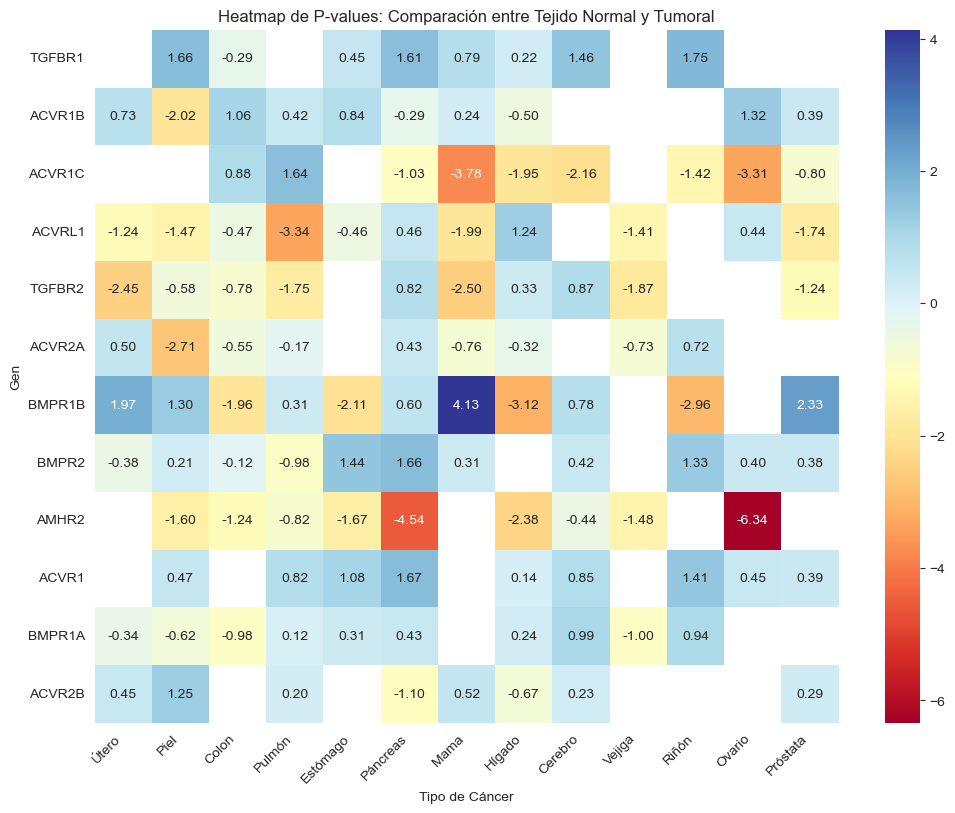

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Crear el DataFrame con los p-values
heatmap_data = merge_pvalue.pivot(index='Gene', columns='ColumnaTraducida', values='p_value').reindex(index=['TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B',
       'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B'], columns=['Útero', 'Piel', 'Colon', 'Pulmón', 'Estómago', 'Páncreas', 'Mama','Hígado', 'Cerebro', 'Vejiga', 'Riñón', 'Ovario',
'Próstata'
])

heatmap_data_2 = merge_pvalue.pivot(index='Gene', columns='ColumnaTraducida', values='dif_tum_norm').reindex(index=['TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B',
       'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B'], columns=['Útero', 'Piel', 'Colon', 'Pulmón', 'Estómago', 'Páncreas', 'Mama','Hígado', 'Cerebro', 'Vejiga', 'Riñón', 'Ovario',
'Próstata'
])

# Convertir los valores de p-value a numéricos
heatmap_data = heatmap_data.apply(pd.to_numeric, errors='coerce')

# Crear máscaras
mask_mayores = heatmap_data > 0.01  # para mostrar p-values <= 0.01 (logaritmo)
mask_menores = heatmap_data <= 0.01   # para p-values > 0.01 (logaritmo)

# Configurar el tamaño del gráfico
plt.figure(figsize=(12, 9))

# Crear dos mapas de colores personalizados
cmap_menores = sns.color_palette(["#FFFFFF"])  # Blanco para p-values <= 0.01
cmap_mayores = sns.color_palette(["#324597"])  # Azul marino para p-values > 0.01


# Crear el heatmap para los valores de expresión, sólo para celdas con p-values > 0.05
sns.heatmap(heatmap_data_2, annot=True, fmt=".2f", cmap='RdYlBu', cbar=True, mask=~mask_menores, linewidths=0,linecolor='white')

# Ajustar las etiquetas del eje y para que estén horizontales
plt.gca().set_yticklabels(plt.gca().get_yticklabels(), rotation=0)
plt.gca().set_xticklabels(plt.gca().get_xticklabels(), rotation=45, ha='right')  # Rotar las etiquetas y alinearlas a la derecha

# Añadir títulos y etiquetas
plt.title('Heatmap de P-values: Comparación entre Tejido Normal y Tumoral')
plt.xlabel('Tipo de Cáncer')
plt.ylabel('Gen')

plt.grid(False)

# Guardar el gráfico en formato SVG antes de mostrarlo
plt.savefig("../run/imagenes/heatmap_mutation_expresion.svg", format='svg')

# Mostrar el gráfico
plt.show()



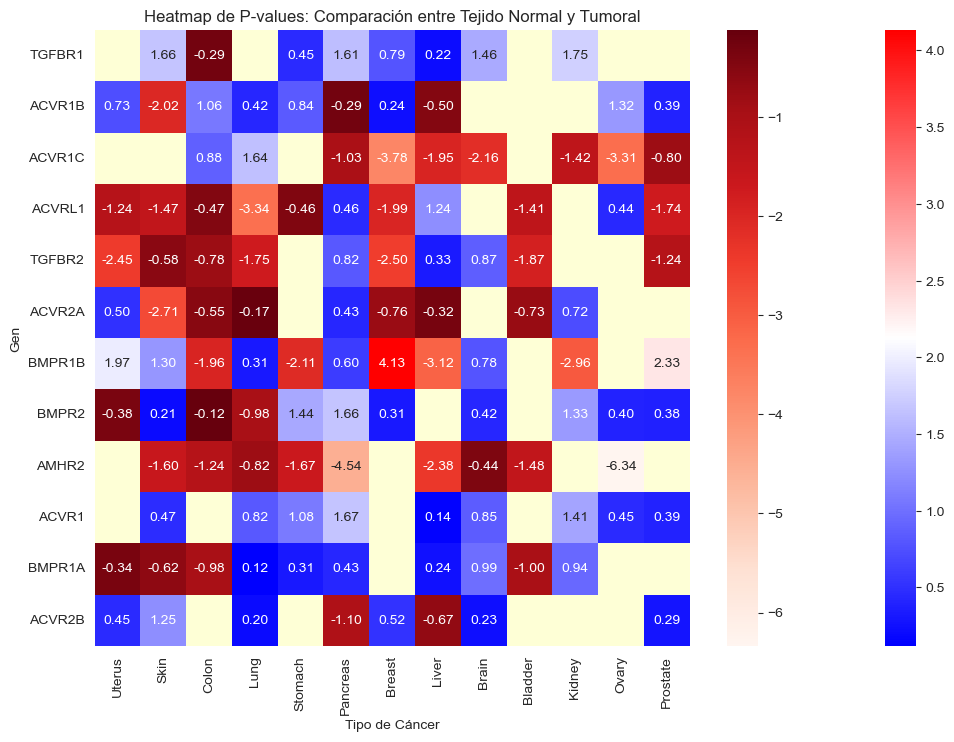

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Crear el DataFrame con los p-values
heatmap_data = merge_pvalue.pivot(index='Gene', columns='_primary_site', values='p_value_log').reindex(index=['TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B',
       'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B'], columns=['Uterus', 'Skin', 'Colon', 'Lung', 'Stomach', 'Pancreas', 'Breast', 'Liver', 'Brain', 'Bladder', 'Kidney', 'Ovary',
'Prostate'
])

heatmap_data_2 = merge_pvalue.pivot(index='Gene', columns='_primary_site', values='dif_tum_norm').reindex(index=['TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B',
       'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B'], columns=['Uterus', 'Skin', 'Colon', 'Lung', 'Stomach', 'Pancreas', 'Breast', 'Liver', 'Brain', 'Bladder', 'Kidney', 'Ovary',
'Prostate'
])
# Convertir los valores de p-value a numéricos
heatmap_data = heatmap_data.apply(pd.to_numeric, errors='coerce')

# Crear una máscara para los p-values mayores a 0.01 (logaritmo)
mask_mayores = heatmap_data < -2
mask_menores = heatmap_data >= -2

# Crear máscaras para promedios positivos y negativos, excluyendo los p-values menores a 0.05
mean_positivo = (heatmap_data_2 > 0) & mask_mayores  # Solo aplica a promedios positivos donde p-value es mayor
mean_negativo = (heatmap_data_2 <= 0) & mask_mayores  # Solo aplica a promedios negativos donde p-value es mayor

# Crear máscaras para promedios positivos y negativos, excluyendo los p-values menores a 0.05
mean_mayores = (heatmap_data_2 > 0) & mean_positivo  # Solo aplica a promedios positivos 
mean_menores = (heatmap_data_2 <= 0) & mean_positivo  # Solo aplica a promedios positivos

# Configurar el tamaño del gráfico
plt.figure(figsize=(12, 8))

# Crear dos mapas de colores personalizados: uno para menores o iguales a 0.05 y otro para mayores a 0.05
cmap_menores = sns.color_palette(["#feffd6"])  # Amarillo pálido (#FFFACD) para p-values <= 0.05
cmap_mayores = sns.color_palette(["#324597"])  # azul marino (#FF4500) para p-values > 0.05
cmap_positivo = sns.color_palette(["#003785"]) # azul oscuro (diferencia positiva)
cmap_negativo = sns.color_palette(["#def7ff"]) # celeste  (diferencia negativa)
# Crear el heatmap para los p-values menores o iguales a 0.05
sns.heatmap(heatmap_data, annot=False, fmt=".2f", cmap=cmap_menores, mask=~mask_menores, cbar=False)

# Crear el heatmap para los p-values mayores a 0.05
sns.heatmap(heatmap_data, annot=False, fmt=".2f", cmap=cmap_mayores, mask=~mask_mayores, cbar=False)

# Crear el heatmap para promedios positivos
sns.heatmap(heatmap_data_2, annot=True, fmt=".2f", cmap='bwr', mask=~mean_positivo, cbar=True)

# Crear el heatmap para promedios negativos
sns.heatmap(heatmap_data_2, annot=True, fmt=".2f", cmap='Reds', mask=~mean_negativo, cbar=True)

# Añadir títulos y etiquetas
plt.title('Heatmap de P-values: Comparación entre Tejido Normal y Tumoral')
plt.xlabel('Tipo de Cáncer')
plt.ylabel('Gen')

# Mostrar el gráfico
plt.show()



## t student

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import pingouin as pg

# Define los genes que deseas analizar
gen_list = ['BMPR1B', 'ACVR2A', 'BMPR1A', 'ACVR1B', 'TGFBR1', 'ACVRL1',
            'TGFBR2', 'ACVR1', 'ACVR2B', 'BMPR2', 'AMHR2', 'ACVR1C']

# Define los tipos de cáncer y el tipo de muestra que deseas analizar
sites = ['Uterus', 'Skin', 'Colon', 'Lung', 'Stomach', 'Pancreas', 'Breast',
            'Head and Neck region', 'Liver', 'Brain', 'Bladder', 'Cervix', 'Kidney', 'Ovary',
            'Prostate', 'Gland', 'Blood']

sample_types = ['Normal Tissue', 'Primary Tumor']

# Filtrar los datos para Normal Tissue y Primary Tumor
clinexp_filtered = clinexp.loc[
    (clinexp['_primary_site'].isin(sites)) & 
    (clinexp['_sample_type'].isin(sample_types))
]

# Normalizar los datos de expresión
for gen in gen_list:
    clinexp_filtered[gen] = clinexp_filtered[gen] / clinexp_filtered[gen].max()

# Convertir los datos a formato largo para seaborn
clinexp_long = clinexp_filtered.melt(id_vars=['_primary_site', '_sample_type'], 
                                      value_vars=gen_list, 
                                      var_name='Gene', 
                                      value_name='Normalized Expression')

# DataFrame vacío para almacenar resultados del T-test
results = []

# Aplicar el T-test para cada gen y sitio de cáncer
for gene in gen_list:
    for site in sites:
        # Filtrando los datos
        normal_expr = clinexp_long[(clinexp_long['Gene'] == gene) & 
                                   (clinexp_long['_primary_site'] == site) & 
                                   (clinexp_long['_sample_type'] == 'Normal Tissue')]['Normalized Expression']
        tumoral_expr = clinexp_long[(clinexp_long['Gene'] == gene) & 
                                    (clinexp_long['_primary_site'] == site) & 
                                    (clinexp_long['_sample_type'] == 'Primary Tumor')]['Normalized Expression']

        # Realizando el T-test
        if len(normal_expr) > 0 and len(tumoral_expr) > 0:
            t_test_result = pg.ttest(x=normal_expr, y=tumoral_expr, alternative='two-sided')
            stat = t_test_result['T'][0]
            p_value = t_test_result['p-val'][0]
            
            # Guardando los resultados
            results.append({'Gene': gene, '_primary_site': site, 'stat': stat, 'p_value': p_value})

# Convirtiendo los resultados en un dataframe
results_df_t = pd.DataFrame(results)

# Mostrar los resultados
results_df_t


/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_5921/4288240442.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clinexp_filtered[gen] = clinexp_filtered[gen] / clinexp_filtered[gen].max()
/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_5921/4288240442.py:50: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  stat = t_test_result['T'][0]
/var/folders/17/bt4jbx0920sgdvwfqnkx2bnr0000gn/T/ipykernel_5921/4288240442.py:51: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be 

,Gene,_primary_site,stat,p_value
0,BMPR1B,Uterus,-9.537438,9.623515e-16
1,BMPR1B,Skin,-5.782441,7.671198e-08
2,BMPR1B,Colon,11.436000,1.646472e-27
3,BMPR1B,Lung,-3.444686,6.018295e-04
4,BMPR1B,Stomach,14.952953,9.927045e-43
...,...,...,...,...
151,ACVR1C,Brain,25.640471,3.708854e-115
152,ACVR1C,Bladder,0.253079,8.060478e-01
153,ACVR1C,Kidney,4.967507,2.542007e-05
154,ACVR1C,Ovary,18.505917,7.349850e-39


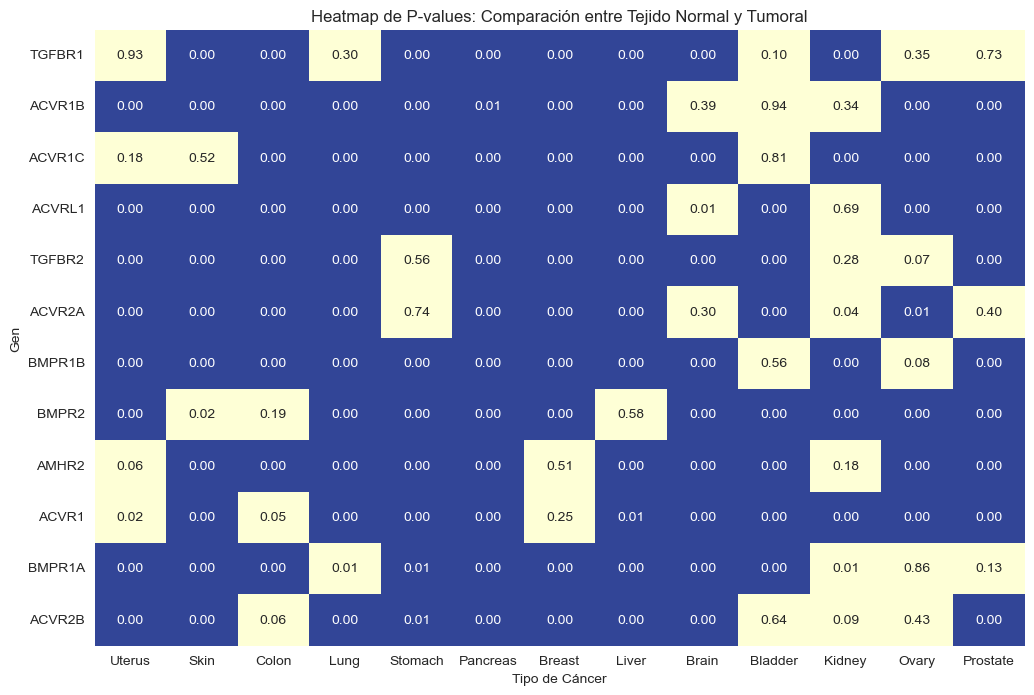

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Crear el DataFrame con los p-values
heatmap_data = results_df_t.pivot(index='Gene', columns='_primary_site', values='p_value').reindex(index=['TGFBR1', 'ACVR1B', 'ACVR1C', 'ACVRL1', 'TGFBR2', 'ACVR2A', 'BMPR1B',
       'BMPR2', 'AMHR2', 'ACVR1', 'BMPR1A', 'ACVR2B'], columns=['Uterus', 'Skin', 'Colon', 'Lung', 'Stomach', 'Pancreas', 'Breast', 'Liver', 'Brain', 'Bladder', 'Kidney', 'Ovary',
'Prostate'
])

# Convertir los valores de p-value a numéricos
heatmap_data = heatmap_data.apply(pd.to_numeric, errors='coerce')

# Crear una máscara para los p-values mayores a 0.05
mask_mayores = heatmap_data > 0.01
mask_menores = heatmap_data <= 0.01

# Configurar el tamaño del gráfico
plt.figure(figsize=(12, 8))

# Crear dos mapas de colores personalizados: uno para menores o iguales a 0.05 y otro para mayores a 0.05
cmap_mayores = sns.color_palette(["#feffd6"])  # Amarillo pálido (#FFFACD) para p-values <= 0.05
cmap_menores = sns.color_palette(["#324597"])  # Rojo (#FF4500) para p-values > 0.05

# Crear el heatmap para los p-values menores o iguales a 0.05
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap=cmap_menores, mask=~mask_menores, cbar=False)

# Crear el heatmap para los p-values mayores a 0.05
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap=cmap_mayores, mask=~mask_mayores, cbar=False)

# Añadir títulos y etiquetas
plt.title('Heatmap de P-values: Comparación entre Tejido Normal y Tumoral')
plt.xlabel('Tipo de Cáncer')
plt.ylabel('Gen')

# Mostrar el gráfico
plt.show()
